# Experiment No: 6

## Time Series Analysis of Website Traffic

**Aim:** To analyze the time series data of website traffic to identify trends, seasonality and anomalies.

In [1]:
%pip install -q statsmodels
%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

page_views = [
    120, 135, 128, 140, 150, 145, 160, 155, 170, 165,
    180, 175, 190, 185, 200, 195, 210, 205, 220, 215,
    230, 225, 240, 235, 250, 245, 260, 255, 270, 265,
    280, 275, 290, 285, 300, 295, 310, 305, 320, 315,
    330, 325, 340, 335, 750, 345, 360, 355, 370, 365,
    380, 375, 390, 385, 400, 395, 410, 405, 420, 415,
    430, 425, 440, 435, 450, 445, 460, 455, 470, 465,
    480, 475, 490, 485, 500, 495, 510, 505, 520, 515,
    530, 525, 540, 535, 550, 545, 560, 555, 570, 565
]

data = pd.DataFrame({
    'Date': pd.date_range(start='2025-01-01', periods=90, freq='D'),
    'Page_Views': page_views,
    'Unique_Visitors': [int(v * 0.7) for v in page_views],
    'Bounce_Rate': [round(35 + (v % 10), 1) for v in page_views]
})
data.to_csv('website_traffic.csv', index=False)
print("website_traffic.csv created successfully")

Note: you may need to restart the kernel to use updated packages.


website_traffic.csv created successfully


            Page_Views  Unique_Visitors  Bounce_Rate
Date                                                
2025-01-01         120               84           35
2025-01-02         135               94           40
2025-01-03         128               89           43
2025-01-04         140               98           35
2025-01-05         150              105           35


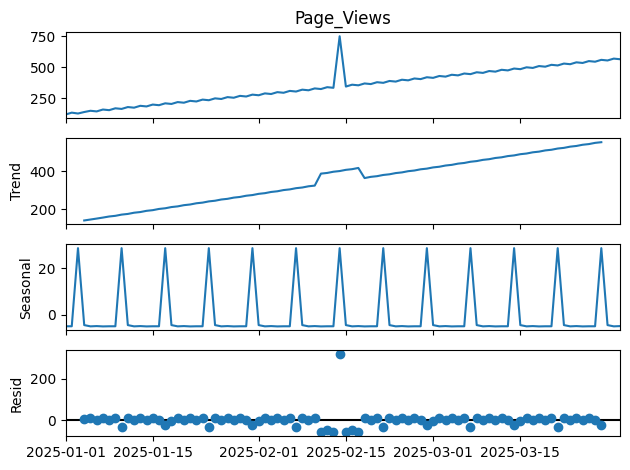

In [2]:
# Load dataset
data = pd.read_csv('website_traffic.csv', parse_dates=['Date'], index_col='Date')
print(data.head())

# Time Series Decomposition
decomposition = seasonal_decompose(data['Page_Views'], model='additive', period=7)
decomposition.plot()
plt.show()

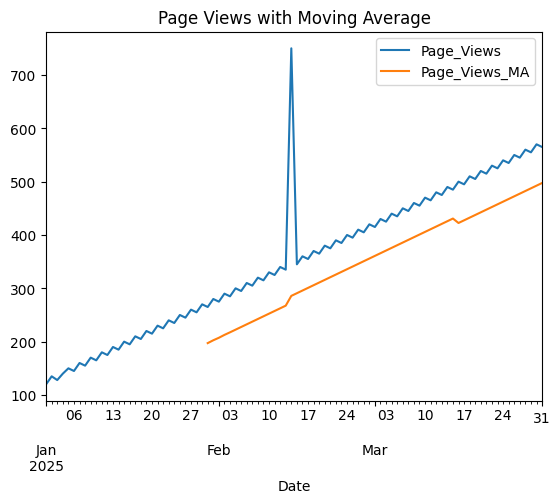

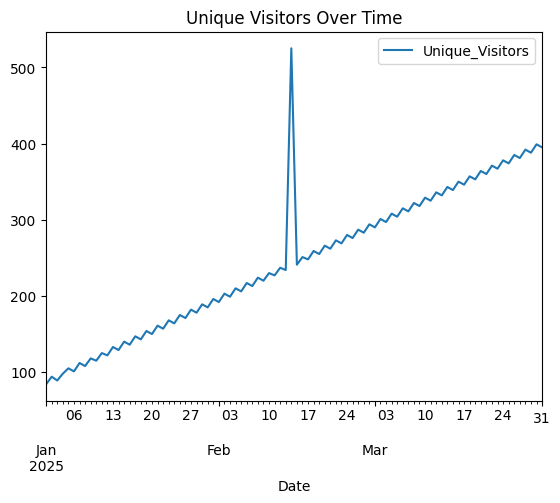

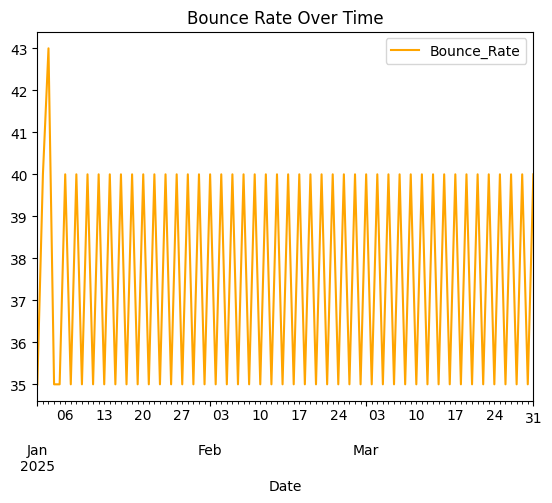

In [3]:
# Moving Average
data['Page_Views_MA'] = data['Page_Views'].rolling(window=30).mean()
data[['Page_Views', 'Page_Views_MA']].plot()
plt.title('Page Views with Moving Average')
plt.show()

# Plot Unique_Visitors and Bounce_Rate
data[['Unique_Visitors']].plot()
plt.title('Unique Visitors Over Time')
plt.show()

data[['Bounce_Rate']].plot(color='orange')
plt.title('Bounce Rate Over Time')
plt.show()

Anomalies detected:
Empty DataFrame
Columns: [Page_Views, Page_Views_Z]
Index: []


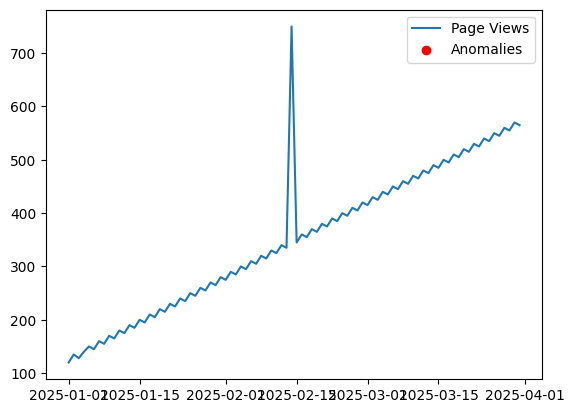

In [4]:
# Anomaly Detection using Z-score
data['Page_Views_Z'] = (data['Page_Views'] - data['Page_Views'].mean()) / data['Page_Views'].std()
anomalies = data[data['Page_Views_Z'].abs() > 3]
print("Anomalies detected:")
print(anomalies[['Page_Views', 'Page_Views_Z']])

plt.plot(data.index, data['Page_Views'], label='Page Views')
plt.scatter(anomalies.index, anomalies['Page_Views'], color='red', label='Anomalies')
plt.legend()
plt.show()